In [2]:
import os
import numpy as np
import xarray as xr
import cupy as cp
import cupyx.scipy.ndimage as GPUndimage
from cucim.skimage.morphology import ball as GPUball
from time import sleep
from joblib import delayed, Parallel
import subprocess

num_GPU=5
GPUlimit = 0.5
njobs = 16


def find_free_GPU_memory(gpu_id, limit=GPUlimit, num_GPU=num_GPU):
    free = cp.cuda.Device(gpu_id).mem_info[0]/cp.cuda.Device(gpu_id).mem_info[1]
    
    while free<limit:
        gpu_id = (gpu_id+1)%num_GPU #for all available GPUs
        sleep(2)
        free = cp.cuda.Device(gpu_id).mem_info[0]/cp.cuda.Device(gpu_id).mem_info[1]
        
    return gpu_id

toppath = '/mnt/SSD/fische_r/COELY/05_water_GDL_ML'
gitpath = '/mpc/homes/fische_r/lib/co2ely-tomcat'

In [3]:
def timestep_function(im, i):
    gpu_id = i%num_GPU
    gpu_id = find_free_GPU_memory(gpu_id)
    
    with cp.cuda.Device(gpu_id):
        imgpu = cp.array(im)
        imgpu = GPUndimage.median_filter(imgpu, footprint=GPUball(1))
        imgpu = GPUndimage.binary_fill_holes(imgpu)
        im = cp.asnumpy(imgpu)
        del imgpu
        mempool = cp.get_default_memory_pool()
        mempool.free_all_blocks()
    return im

In [4]:
sample = '4'

In [5]:
datapath = os.path.join(toppath, sample, sample+'water_segmentation.nc')

In [6]:
data = xr.open_dataset(datapath)

In [16]:
ts = 10
z = 1200

In [8]:
im =data['segmented'][...,ts].data

In [9]:
import matplotlib.pyplot as plt

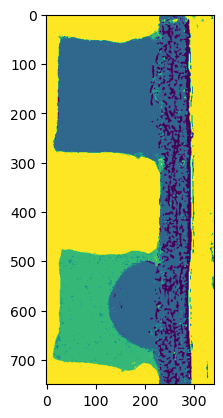

In [21]:
plt.imshow(im[:,:,z])

In [18]:
water = im == 2

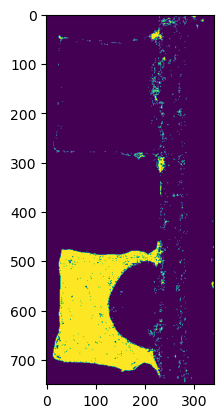

In [20]:
plt.imshow(water[:,:,z])

In [22]:
imgpu = cp.array(water)

In [23]:
imgpu = GPUndimage.median_filter(imgpu, footprint=GPUball(1))
imgpu = GPUndimage.binary_fill_holes(imgpu)

In [24]:
water_filt = cp.asnumpy(imgpu)

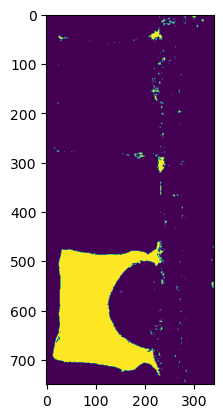

In [27]:
plt.imshow(water_filt[:,:,z])

In [28]:
imgpu = GPUndimage.label(imgpu)

In [31]:
water_label = cp.asnumpy(imgpu[0])

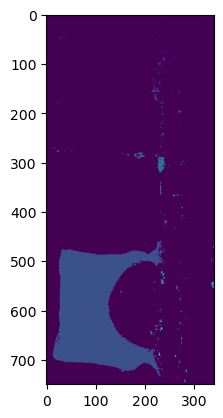

In [32]:
plt.imshow(water_label[:,:,z])

In [38]:
slug_labels, counts = cp.unique(imgpu[0][:,:150,:], return_counts=True)

In [34]:
slug_labels

array([     0,      1,      2, ..., 236658, 237769, 238064], dtype=int32)

In [49]:
np.count_nonzero(counts>30)

array(1332)

In [50]:
rel_labels = slug_labels[counts>20][1:]

In [48]:
slug_water = cp.zeros(water.shape, dtype=bool)

In [52]:
for i in rel_labels:
    slug_water[imgpu[0]==i] = True

In [53]:
water_slug = cp.asnumpy(slug_water)

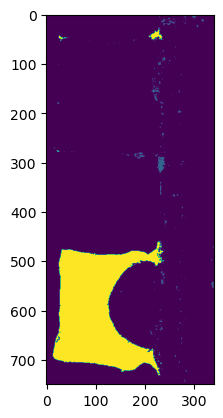

In [56]:
plt.imshow(water_slug[:,:,z]*2+water_filt[:,:,z])